# COMP7015 Group Project – Topic 1: Plant Disease Classification

We classify tomato leaf images from the [PlantVillage dataset](https://github.com/spMohanty/PlantVillage-Dataset) into **healthy, bacterial spot, early blight and late blight**. We compare a custom CNN with Squeeze-and-Excitation attention, a fine-tuned ResNet18 and a fine-tuned Vision Transformer (ViT-B/16). The photo backgrounds differ between the classes, so we also ask how robust the models are.

The project has two notebooks, run in this order:
- **`01_classification.ipynb` (this notebook):** the data protocol (Sections 1–6), the custom CNN and ResNet18 (7–9), the ViT (10), the final test evaluation, compute trade-offs and error analysis (11–13), and the summary and discussion of these results (21, 22.1–22.3).
- **`02_robustness.ipynb`:** robustness to the background, colour, lighting, image quality and field photos (14–20), with its own summary and discussion (21, 22.4–22.6).

The shared code is in the `plantdisease/` package. Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so re-running the notebook only loads them.

# Part 1: Data

Sections 1–6: configuration, download, leaf grouping, image cache, leaf-group split with leakage audit, and augmentation.

## 1. Setup & Configuration

The settings live in four dictionaries in `plantdisease/config.py`: `PATHS_CONFIG` (where data and results live), `DATA_CONFIG` (the PlantVillage protocol), `PLANTDOC_CONFIG` (the PlantDoc field photos) and `TRAIN_CONFIG` (training seeds, background-swap probability).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import Markdown, display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from torchinfo import summary

from plantdisease.config import (
    DATA_CONFIG,
    PATHS_CONFIG,
    SHORT_NAMES,
    TRAIN_CONFIG,
    out_path,
    save_config,
)
from plantdisease.data.dataset import prepare
from plantdisease.data.download import download_plantvillage
from plantdisease.data.loaders import CachedDataset, make_loader, train_tf
from plantdisease.data.records import load_records
from plantdisease.device import USE_AMP, device
from plantdisease.evaluate import (
    compare_seeds,
    inference_cost,
    mean_sd,
    per_class_f1,
    sd,
    seed_scores,
    stable_errors,
    training_cost,
)
from plantdisease.experiments import (
    BASE_CNN,
    BASE_RESNET,
    BASE_VIT,
    CNN_EXPERIMENTS,
    RESNET_EXPERIMENTS,
    VIT_EXPERIMENTS,
    changes_table,
    config_of,
    load_final_models,
    save_selected,
)
from plantdisease.gradcam import cam_images
from plantdisease.models import build_model, count_params, set_trainable
from plantdisease.plots import finish, mean_curve, show_batch
from plantdisease.predictions import predict_labels, predict_probs
from plantdisease.train import run

save_config()  # all settings -> OUT_DIR/config.json
TUNING_SEED = TRAIN_CONFIG["tuning_seed"]  # one seed for the tuning runs and ablations (Section 9)

In [2]:
DATA_CONFIG

{'classes': ['Tomato___healthy',
  'Tomato___Bacterial_spot',
  'Tomato___Early_blight',
  'Tomato___Late_blight'],
 'img_size': 224,
 'split_seed': 62,
 'split_fractions': (0.7, 0.15),
 'num_workers': 2}

In [3]:
print("Device in use:", device, "| mixed precision:", USE_AMP)
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

Device in use: cuda:0 | mixed precision: True
torch 2.15.0+cu132 | torchvision 0.29.2+cu132


## 2. Download the Data

We download the whole PlantVillage repository. We use the four tomato folders of `raw/color` (the RGB images used for training). We also use `raw/segmented`, the same photos with the background removed.

In [4]:
download_plantvillage()  # git clone of the whole repository, skipped if it exists
for kind in ("color", "segmented"):
    for class_name in DATA_CONFIG["classes"]:
        folder = f"raw/{kind}/{class_name}"
        n_images = len(os.listdir(os.path.join(PATHS_CONFIG["data_root"], folder)))
        print(f"{folder:60s} {n_images} images")

raw/color/Tomato___healthy                                   1591 images
raw/color/Tomato___Bacterial_spot                            2127 images
raw/color/Tomato___Early_blight                              1000 images
raw/color/Tomato___Late_blight                               1909 images
raw/segmented/Tomato___healthy                               1591 images
raw/segmented/Tomato___Bacterial_spot                        2127 images
raw/segmented/Tomato___Early_blight                          1000 images
raw/segmented/Tomato___Late_blight                           1909 images


## 3. Leaf Grouping & Label Verification

Every image must be assigned to a **physical leaf**, so that all photos of one leaf end up in the same split.

1. **Official metadata.** The image identifier from the file name is looked up in `leaf-map.json`, keeping only an entry of the image's own class. Most leaves are photographed four times.
2. **Official leaf ids only.** We use every photo of the four classes that has an official leaf id.
3. **Exclusion.** Photos without an official leaf id are excluded (`OUT_DIR/excluded_images.csv`): greenhouse photos whose leaf number can only be parsed from the file name, and photos without any leaf information.

In [5]:
# every photo of the four classes with its leaf id from leaf-map.json (plantdisease/data/records.py)
all_df = load_records()
# photos without an official leaf id (file-name leaf number only, or no leaf information) are excluded
all_df[all_df["source"] != "leaf map"].to_csv(
    out_path("excluded_images.csv"), index=False
)

pd.crosstab(all_df["class_name"], all_df["source"], margins=True).reindex(
    [*DATA_CONFIG["classes"], "All"]
)

source,excluded: no leaf information,file name,leaf map,All
class_name,,,,
Tomato___healthy,2,590,999,1591
Tomato___Bacterial_spot,0,0,2127,2127
Tomato___Early_blight,1,0,999,1000
Tomato___Late_blight,541,448,920,1909
All,544,1038,5045,6627


## 4. Image Cache

**Caching.** Decoding JPEGs and resizing them in every epoch is wasted work. Each image is decoded, converted to RGB and resized to 224×224 **once**, then stored as one `uint8` tensor in `cache/`. Training then only applies cheap tensor operations. The cache is rebuilt automatically if the image list or size changes.

In [6]:
# prepare() runs the whole data protocol: the photos with an official leaf id (Section 3),
# their images decoded + resized once, uint8 (N, 3, 224, 224), and the split (Section 5)
data = prepare()
df, images = data.df, data.images
print(f"Cached images: {tuple(images.shape)}, {images.numel() / 1e9:.2f} GB")

Cached images: (5045, 3, 224, 224), 0.76 GB


In [7]:
df

,path,file_name,class_index,class_name,image_key,leaf_id,source,split
0,./PlantVillage-Dataset\raw\color\Tomato___heal...,0031da2a-8edd-468f-a8b1-106657717a32___RS_HL 0...,0,Tomato___healthy,rs_hl 0105,Tomato___healthy:::26.0,leaf map,train
1,./PlantVillage-Dataset\raw\color\Tomato___heal...,003944fc-3b99-4a0f-9ed4-0e07352fd8b3___RS_HL 9...,0,Tomato___healthy,rs_hl 9844,Tomato___healthy:::214.0,leaf map,train
2,./PlantVillage-Dataset\raw\color\Tomato___heal...,00bce074-967b-4d50-967a-31fdaa35e688___RS_HL 0...,0,Tomato___healthy,rs_hl 0223,Tomato___healthy:::56.0,leaf map,train
3,./PlantVillage-Dataset\raw\color\Tomato___heal...,014b5e19-7917-4d76-b632-b5dd31d999ec___RS_HL 9...,0,Tomato___healthy,rs_hl 9640,Tomato___healthy:::163.0,leaf map,train
4,./PlantVillage-Dataset\raw\color\Tomato___heal...,01700b46-3800-46c6-ab81-09a5f50af525___RS_HL 0...,0,Tomato___healthy,rs_hl 0108,Tomato___healthy:::27.0,leaf map,train
...,...,...,...,...,...,...,...,...
5040,./PlantVillage-Dataset\raw\color\Tomato___Late...,fce57140-eb13-4c01-8a18-88dc5e8a75dc___RS_Late...,3,Tomato___Late_blight,rs_late.b 4923,Tomato___Late_blight:::18.0,leaf map,test
5041,./PlantVillage-Dataset\raw\color\Tomato___Late...,fce9cc3f-88ab-46d6-a26f-c6ff0e7c56e7___RS_Late...,3,Tomato___Late_blight,rs_late.b 6372,Tomato___Late_blight:::162.0,leaf map,train
5042,./PlantVillage-Dataset\raw\color\Tomato___Late...,fe416307-5c50-4c9f-96b5-f6e15ef79045___RS_Late...,3,Tomato___Late_blight,rs_late.b 4975,Tomato___Late_blight:::27.0,leaf map,train
5043,./PlantVillage-Dataset\raw\color\Tomato___Late...,ff3ddd95-9c84-42fb-aef3-eceb2d5b1110___RS_Late...,3,Tomato___Late_blight,rs_late.b 4831,Tomato___Late_blight:::1.0,leaf map,test


## 5. Leaf-Group Split & Leakage Audit

Within each class, the official leaf ids are shuffled with a fixed seed and split 70 / 15 / 15 into train / validation / test. All photos of one leaf follow its leaf id. The split seed is separate from the training seeds, so all models and seeds share **exactly the same split**. The audit asserts that no official leaf id appears in two splits.

In [8]:
# 70/15/15 split of the official leaf ids of every class; the audit is asserted inside make_split
print(
    f"Split seed: {DATA_CONFIG['split_seed']} | every official leaf id lies in exactly one split"
)

df[["path", "class_name", "leaf_id", "split"]].to_csv(
    out_path("split.csv"), index=False
)
counts = pd.crosstab(df["class_name"], df["split"], margins=True).reindex(
    [*DATA_CONFIG["classes"], "All"]
)[["train", "val", "test", "All"]]
counts["leaf ids"] = [
    *df.groupby("class_name")["leaf_id"]
    .nunique()
    .reindex(DATA_CONFIG["classes"])
    .tolist(),
    df.leaf_id.nunique(),
]
counts.to_csv(out_path("class_counts.csv"))
counts

Split seed: 62 | every official leaf id lies in exactly one split


split,train,val,test,All,leaf ids
class_name,,,,,
Tomato___healthy,699,152,148,999,250
Tomato___Bacterial_spot,1487,320,320,2127,532
Tomato___Early_blight,699,152,148,999,250
Tomato___Late_blight,644,136,140,920,230
All,3529,760,756,5045,1262


## 6. Preprocessing, Augmentation & Class Weights

The cached images are already resized to 224×224 (the whole photo, no crop). Every split is converted to float in [0, 1] and normalised with the ImageNet mean/std. The same preprocessing is used for all models, including the ViT.

**Training-only augmentation** must not change the symptoms:
- horizontal/vertical flips and **rotations by multiples of 90°**, because a leaf has no fixed orientation. These rotations are lossless and add no black corners, which matters because the background could carry class information (Section 4).
- a mild brightness/contrast jitter (±10%) for lighting changes. There is no hue/saturation change, so lesion colours (yellow halos, brown spots, mould) are preserved.

**Class balance.** Spider mites have about 1.7× more training images than the other classes. Rather than throwing data away, the CNNs use a **class-weighted cross-entropy loss** with weight $w_c = N / (K \cdot n_c)$, so errors on smaller classes cost more. Section 9 tests whether this helps. The ViT follows Zhouyang's protocol without class weights (Section 10).

The transforms, the cached dataset and the loaders are defined in `plantdisease/data/`.

Class weights: {'healthy': 1.2619999647140503, 'Bacterial_spot': 0.5929999947547913, 'Early_blight': 1.2619999647140503, 'Late_blight': 1.3700000047683716}


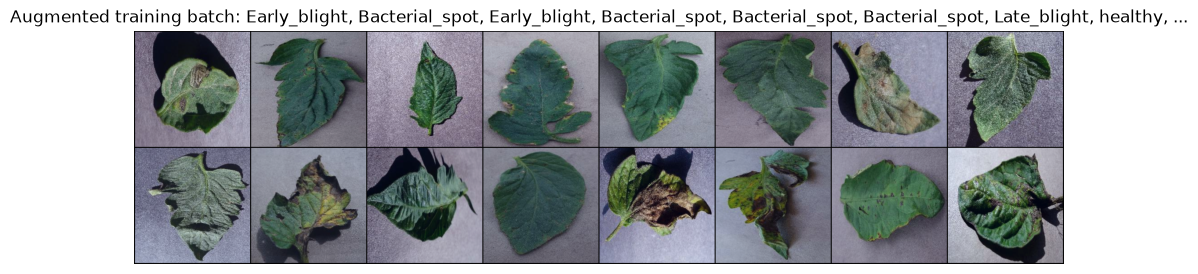

In [9]:
weights = data.class_weights  # w_c = N / (K * n_c)
print(
    "Class weights:",
    dict(zip(SHORT_NAMES, weights.numpy().round(3).tolist(), strict=True)),
)

# Visualise augmented training images
dataset = CachedDataset(images, data.labels, data.train_idx, train_tf)
x, y = next(iter(make_loader(dataset, 16, seed=0)))
show_batch(x, y, "Augmented training batch")

**Hand-over.** The later sections use this `data` object, and `02_robustness.ipynb` gets exactly the same data with the same call, `prepare()` (`plantdisease/data/dataset.py`), which takes a few seconds once the image cache exists. The split is saved to `OUT_DIR/split.csv`.

# Part 2: Custom CNN & ResNet18

Sections 7–9: the custom CNN and ResNet18, the training engine, hyperparameter tuning, ablations and the selection of both models on the validation set.

## 7. Models

| Model | Type | Idea |
|---|---|---|
| **Custom CNN** | trained from scratch | 4 × (Conv 3×3 → BatchNorm → ReLU → MaxPool), global average pooling, dropout, linear |
| **SE-CNN** | trained from scratch + attention | the same CNN with a **Squeeze-and-Excitation** block after every conv layer. SE squeezes each channel to one number (global average), passes the result through a small bottleneck MLP and uses the sigmoid output to **re-weight the channels**. This is a cheap form of attention that lets the network emphasise lesion-detecting filters (Hu et al., 2018). |
| **ResNet18** | transfer learning (CNN) | ImageNet-pretrained, new 4-class head |
| **ViT-B/16** | transfer learning (transformer) | Section 10 |

`set_trainable` implements the freezing used for **two-stage fine-tuning**. In the first stage only the new head is trained, so that the randomly initialised layer does not send large, noisy gradients into the pre-trained backbone. In the second stage the backbone is unfrozen and trained with a smaller learning rate. The models are defined in `plantdisease/models.py` (shared with Part 4 and `02_robustness.ipynb`, which rebuild the models from their checkpoints). Their code and layer shapes are shown below.

### Training recipes

Every model is trained with a **recipe** (`RunConfig`, `plantdisease/experiments.py`): architecture, learning rate, batch size, dropout, augmentation, class weights, learning-rate schedule, weight decay, maximum epochs and early-stopping patience, and for pre-trained models the head-only epochs and their learning rates. The base recipes of the custom CNN and of ResNet18 (`BASE_CNN`, `BASE_RESNET`) are defined in the same file and shown below; Section 9 derives all experiments from them. The maximum epochs and the patience can be set with the environment variables `EPOCHS_*` and `PATIENCE_*` (see the README).

In [10]:
# all settings of both base recipes (settings that a recipe does not list keep their default)
pd.DataFrame(
    {"custom CNN": BASE_CNN.model_dump(), "ResNet18": BASE_RESNET.model_dump()}
)

,custom CNN,ResNet18
arch,se_cnn,resnet18
lr,0.001,0.0001
batch_size,32,32
dropout,0.3,0.0
augment,True,True
class_weights,True,True
scheduler,cosine,cosine
weight_decay,0.0001,0.0001
epochs,50,20
patience,10,5


The tables below are `torchinfo.summary` of each model for one 224 × 224 RGB image: the output shape and the number of parameters of every layer, and the totals. The global average pooling in `CustomCNN.forward` has no module of its own: it turns the last feature map (256 × 14 × 14) into a vector of 256 values, which is the input of the `dropout` layer.

**Custom CNN**

In [11]:
summary(build_model(BASE_CNN.variant(arch="cnn")), input_size=(1, 3, 224, 224), depth=4)

Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN                                [1, 4]                    --
├─Sequential: 1-1                        [1, 256, 14, 14]          --
│    └─Conv2d: 2-1                       [1, 32, 224, 224]         864
│    └─BatchNorm2d: 2-2                  [1, 32, 224, 224]         64
│    └─ReLU: 2-3                         [1, 32, 224, 224]         --
│    └─MaxPool2d: 2-4                    [1, 32, 112, 112]         --
│    └─Conv2d: 2-5                       [1, 64, 112, 112]         18,432
│    └─BatchNorm2d: 2-6                  [1, 64, 112, 112]         128
│    └─ReLU: 2-7                         [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-8                    [1, 64, 56, 56]           --
│    └─Conv2d: 2-9                       [1, 128, 56, 56]          73,728
│    └─BatchNorm2d: 2-10                 [1, 128, 56, 56]          256
│    └─ReLU: 2-11                        [1, 128, 56, 56]          --
│   

**SE-CNN** (an SEBlock after every ReLU keeps the shape and adds parameters)

In [12]:
summary(build_model(BASE_CNN), input_size=(1, 3, 224, 224), depth=4)

Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN                                [1, 4]                    --
├─Sequential: 1-1                        [1, 256, 14, 14]          --
│    └─Conv2d: 2-1                       [1, 32, 224, 224]         864
│    └─BatchNorm2d: 2-2                  [1, 32, 224, 224]         64
│    └─ReLU: 2-3                         [1, 32, 224, 224]         --
│    └─SEBlock: 2-4                      [1, 32, 224, 224]         --
│    │    └─Sequential: 3-1              [1, 32]                   --
│    │    │    └─Linear: 4-1             [1, 4]                    132
│    │    │    └─ReLU: 4-2               [1, 4]                    --
│    │    │    └─Linear: 4-3             [1, 32]                   160
│    │    │    └─Sigmoid: 4-4            [1, 32]                   --
│    └─MaxPool2d: 2-5                    [1, 32, 112, 112]         --
│    └─Conv2d: 2-6                       [1, 64, 112, 112]         18,432
│    └─B

**ResNet18**

In [13]:
summary(
    build_model(BASE_RESNET, pretrained=False), input_size=(1, 3, 224, 224), depth=3
)

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 4]                    --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]           --
│

## 8. Training Engine

`run(name, data, seeds)` (`plantdisease/train.py`) trains the recipe of a run name with every seed and returns one history per seed. One run:
- **AdamW** (Adam with decoupled weight decay), optionally with a **cosine learning-rate schedule** stepped every batch;
- **two-stage fine-tuning** for pre-trained models: `head_epochs` epochs training only the head at `head_lr`, then fine-tuning; in the second stage the head and the backbone can have different learning rates (used by the ViT);
- optional class-weighted loss, **gradient clipping** (norm 1) for stability, and **mixed precision** on CUDA;
- **early stopping**: training stops when the validation macro-F1 has not improved for `patience` epochs (`patience` of the recipes in Section 7: 5 epochs for every model). The count starts with the last training stage, so a pre-trained model always fine-tunes for at least `patience` epochs. A cosine schedule keeps its full length, so a run that stops early ends before its learning rate reaches zero;
- **checkpointing**: the weights of the epoch with the best validation macro-F1 are saved (ties keep the earlier epoch). The history and the exact configuration are saved as JSON. If a run with the same configuration already exists, it is loaded instead of retrained;
- **training cost**: per epoch the training time without validation (measured after the GPU has finished), and the number of trainable parameters.

## 9. Hyperparameter Tuning & Ablations (Validation Set Only)

The runs of 9.1 and 9.2 use training seed 62 and are compared by the **best validation macro-F1**. Section 9.3 repeats the best candidates with all training seeds and selects the final models.

**9.1 Custom CNN.** The full recipe is: SE attention, augmentation, dropout 0.3, class-weighted loss, cosine schedule, batch size 32, AdamW (weight decay 1e-4).
- We first sweep the **learning rate** (3e-4, 1e-3, 3e-3).
- Starting from the full recipe at lr 1e-3, we then **remove one component at a time** (ablation). This shows how much each component contributes. It covers the architecture (attention), augmentation, regularisation (dropout), class balancing and the scheduler, plus a **batch-size** variation.

**9.2 Fine-tuning strategies (ResNet18).**
- (a) **frozen backbone**: head only;
- (b) **full fine-tuning with a constant learning rate**;
- (c) **two-stage fine-tuning with a cosine schedule**, at two backbone learning rates;
- (d) starting from (c) at lr 1e-4: **batch size 64**, **no augmentation** and **weight decay 1e-2**.

All experiments are listed in Section 9.0.

### 9.0 The experiments

All experiments of 9.1 and 9.2 are defined in `plantdisease/experiments.py` (`CNN_EXPERIMENTS`, `RESNET_EXPERIMENTS`) as changes of the base recipes of Section 7. Both notebooks find the recipe of a run by its name (`config_of`).

In [14]:
# what every experiment changes relative to its base recipe
display(changes_table(CNN_EXPERIMENTS, BASE_CNN))
changes_table(RESNET_EXPERIMENTS, BASE_RESNET)

,changes from the base recipe
SE-CNN (full recipe),(base recipe)
SE-CNN lr=3e-4,lr=0.0003
SE-CNN lr=3e-3,lr=0.003
CNN (no attention),arch=cnn
SE-CNN no augmentation,augment=False
SE-CNN no dropout,dropout=0.0
SE-CNN no class weights,class_weights=False
SE-CNN constant lr,scheduler=constant
SE-CNN batch size 64,batch_size=64


,changes from the base recipe
ResNet18 frozen backbone,"scheduler=constant, head_epochs=20"
"ResNet18 full FT, constant lr","scheduler=constant, head_epochs=0"
"ResNet18 two-stage + cosine, lr=1e-4",(base recipe)
"ResNet18 two-stage + cosine, lr=3e-4",lr=0.0003
ResNet18 batch size 64,batch_size=64
ResNet18 no augmentation,augment=False
ResNet18 weight decay 1e-2,weight_decay=0.01


In [15]:
histories = {name: run(name, data, seeds=[TUNING_SEED])[0] for name in CNN_EXPERIMENTS}

Loaded finished run: SE-CNN (full recipe) (seed 62)
Loaded finished run: SE-CNN lr=3e-4 (seed 62)
Loaded finished run: SE-CNN lr=3e-3 (seed 62)
Loaded finished run: CNN (no attention) (seed 62)
Loaded finished run: SE-CNN no augmentation (seed 62)
Loaded finished run: SE-CNN no dropout (seed 62)
Loaded finished run: SE-CNN no class weights (seed 62)
Loaded finished run: SE-CNN constant lr (seed 62)
Loaded finished run: SE-CNN batch size 64 (seed 62)


In [16]:
histories.update(
    {name: run(name, data, seeds=[TUNING_SEED])[0] for name in RESNET_EXPERIMENTS}
)

Loaded finished run: ResNet18 frozen backbone (seed 62)
Loaded finished run: ResNet18 full FT, constant lr (seed 62)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 (seed 62)
Loaded finished run: ResNet18 two-stage + cosine, lr=3e-4 (seed 62)
Loaded finished run: ResNet18 batch size 64 (seed 62)
Loaded finished run: ResNet18 no augmentation (seed 62)
Loaded finished run: ResNet18 weight decay 1e-2 (seed 62)


In [17]:
def summarize(name, h):
    # One row of the tuning table: the recipe and its best validation epoch.
    cfg = config_of(name)
    best = int(np.argmax(h.val_f1))
    return {
        "run": name,
        "arch": cfg.arch,
        "lr": cfg.lr,
        "batch": cfg.batch_size,
        "dropout": cfg.dropout,
        "augment": cfg.augment,
        "class_w": cfg.class_weights,
        "schedule": cfg.scheduler,
        "best_epoch": best + 1,
        "val_acc": h.val_acc[best],
        "val_macro_f1": h.val_f1[best],
        "train_s_per_epoch": np.mean(h.train_time),
    }


tuning = pd.DataFrame([summarize(n, h) for n, h in histories.items()]).set_index("run")
tuning.to_csv(out_path("tuning_results.csv"))

tuning.round(4)

,arch,lr,batch,dropout,augment,class_w,schedule,best_epoch,val_acc,val_macro_f1,train_s_per_epoch
run,,,,,,,,,,,
SE-CNN (full recipe),se_cnn,0.0010,32,0.3,True,True,cosine,43,0.9934,0.9923,5.5564
SE-CNN lr=3e-4,se_cnn,0.0003,32,0.3,True,True,cosine,39,0.9921,0.9901,5.5577
SE-CNN lr=3e-3,se_cnn,0.0030,32,0.3,True,True,cosine,43,0.9934,0.9918,5.3386
CNN (no attention),cnn,0.0010,32,0.3,True,True,cosine,27,0.9921,0.9901,4.2579
SE-CNN no augmentation,se_cnn,0.0010,32,0.3,False,True,cosine,30,0.9921,0.9901,5.3439
SE-CNN no dropout,se_cnn,0.0010,32,0.0,True,True,cosine,41,0.9934,0.9918,5.5174
SE-CNN no class weights,se_cnn,0.0010,32,0.3,True,False,cosine,45,0.9934,0.9923,5.6067
SE-CNN constant lr,se_cnn,0.0010,32,0.3,True,True,constant,17,0.9895,0.9871,5.5815
SE-CNN batch size 64,se_cnn,0.0010,64,0.3,True,True,cosine,50,0.9908,0.9888,5.3179


### 9.3 Do the best candidates stay on top? Selection with all seeds

Differences between neighbouring configurations are often smaller than the run-to-run variation, so a single seed cannot rank them reliably. The three best CNN variants and the two best ResNet18 variants (by the validation macro-F1 of seed 62) are therefore repeated with all training seeds. The **final models are chosen by the mean validation macro-F1 over the seeds**, shown with the standard deviation over the seeds. The test set is not used here.

In [18]:
# Model selection on the validation set: the best candidates are repeated with all training seeds
TOP_K = {"cnn": 3, "resnet18": 2}  # candidates per family
families = {"cnn": CNN_EXPERIMENTS, "resnet18": RESNET_EXPERIMENTS}
rows = []
for family, experiments in families.items():
    top = tuning.loc[list(experiments), "val_macro_f1"].nlargest(TOP_K[family]).index
    for name in top:
        scores = [max(h.val_f1) for h in run(name, data)]  # all training seeds
        rows.append(
            {
                "family": family,
                "run": name,
                f"val macro-F1 (seed {TUNING_SEED})": tuning.at[name, "val_macro_f1"],
                "mean over seeds": np.mean(scores),
                "mean ± sd": mean_sd(scores),
            }
        )
multi_seed = pd.DataFrame(rows).set_index("run")
multi_seed.to_csv(out_path("tuning_multi_seed.csv"))

selected = {}  # family -> the candidate with the best mean over the seeds
for family in families:
    best = multi_seed.loc[multi_seed.family == family, "mean over seeds"].idxmax()
    selected[family] = best
    save_selected(family, best)  # OUT_DIR/final_models.json, read in Section 11 and by 02_robustness.ipynb
    print(f"Selected {family}: {best}")
multi_seed.round(4)

Loaded finished run: SE-CNN (full recipe) (seed 62)
Loaded finished run: SE-CNN (full recipe) (seed 63)
Loaded finished run: SE-CNN (full recipe) (seed 64)
Loaded finished run: SE-CNN no class weights (seed 62)
Loaded finished run: SE-CNN no class weights (seed 63)
Loaded finished run: SE-CNN no class weights (seed 64)
Loaded finished run: SE-CNN lr=3e-3 (seed 62)
Loaded finished run: SE-CNN lr=3e-3 (seed 63)
Loaded finished run: SE-CNN lr=3e-3 (seed 64)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 (seed 62)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 (seed 63)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 (seed 64)
Loaded finished run: ResNet18 weight decay 1e-2 (seed 62)
Loaded finished run: ResNet18 weight decay 1e-2 (seed 63)
Loaded finished run: ResNet18 weight decay 1e-2 (seed 64)
Selected cnn: SE-CNN lr=3e-3
Selected resnet18: ResNet18 two-stage + cosine, lr=1e-4


,family,val macro-F1 (seed 62),mean over seeds,mean ± sd
run,,,,
SE-CNN (full recipe),cnn,0.9923,0.9906,0.9906 ± 0.0030
SE-CNN no class weights,cnn,0.9923,0.9884,0.9884 ± 0.0053
SE-CNN lr=3e-3,cnn,0.9918,0.9910,0.9910 ± 0.0007
"ResNet18 two-stage + cosine, lr=1e-4",resnet18,1.0000,1.0000,1.0000 ± 0.0000
ResNet18 weight decay 1e-2,resnet18,1.0000,1.0000,1.0000 ± 0.0000


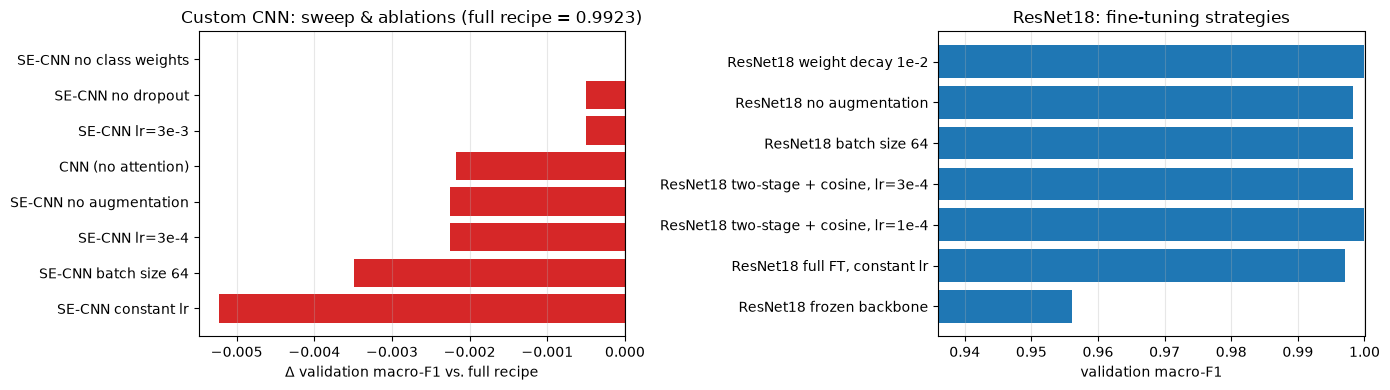

In [19]:
# Ablation chart: change in validation macro-F1 relative to the full CNN recipe
ref = tuning.loc["SE-CNN (full recipe)", "val_macro_f1"]
delta = (tuning.loc[list(CNN_EXPERIMENTS)[1:], "val_macro_f1"] - ref).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].barh(
    delta.index,
    delta.values,
    color=["tab:red" if d < 0 else "tab:green" for d in delta.values],
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Δ validation macro-F1 vs. full recipe")
axes[0].set_title(f"Custom CNN: sweep & ablations (full recipe = {ref:.4f})")
ft = tuning.loc[list(RESNET_EXPERIMENTS), "val_macro_f1"]
axes[1].barh(ft.index, ft.values, color="tab:blue")
axes[1].set_xlim(ft.min() - 0.02, 1.0)
axes[1].set_xlabel("validation macro-F1")
axes[1].set_title("ResNet18: fine-tuning strategies")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
finish("ablations.png")

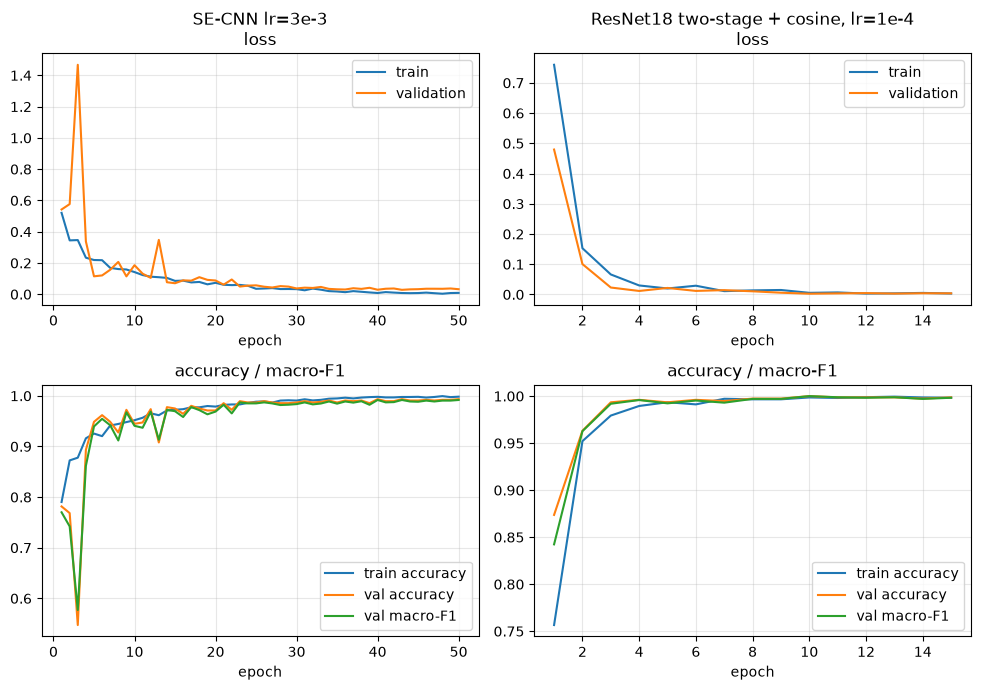

In [20]:
# Learning curves of the selected models (tuning seed)
fig, axes = plt.subplots(2, len(selected), figsize=(5 * len(selected), 7))
for col, name in enumerate(selected.values()):
    h = histories[name]
    epochs = range(1, len(h.train_loss) + 1)
    axes[0, col].plot(epochs, h.train_loss, label="train")
    axes[0, col].plot(epochs, h.val_loss, label="validation")
    axes[0, col].set_title(f"{name}\nloss")
    axes[1, col].plot(epochs, h.train_acc, label="train accuracy")
    axes[1, col].plot(epochs, h.val_acc, label="val accuracy")
    axes[1, col].plot(epochs, h.val_f1, label="val macro-F1")
    axes[1, col].set_title("accuracy / macro-F1")
    for ax in axes[:, col]:
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
finish("learning_curves.png")

# Part 3: Vision Transformer

Section 10: three fine-tuning strategies for a pre-trained ViT-B/16 and an augmentation ablation, and the selection of the final ViT on the validation set.

## 10. ViT-B/16 Fine-Tuning

**Model.** torchvision's ViT-B/16 with ImageNet-1K weights. The 224×224 image is cut into 14×14 = 196 patches of 16×16 pixels; together with a class token they pass through 12 self-attention blocks that relate every patch to every other patch (Lab 5). The ImageNet head is replaced by a 4-class linear layer (3,076 parameters); the model has 85.8 M parameters in total.

**Fine-tuning strategies.** All strategies first train **only the new head for 3 epochs**. From epoch 4 they differ only in which parameters are unfrozen:

| Strategy | Epochs 1–3 | Epochs 4–15 |
|---|---|---|
| **head only** | head | head; the backbone stays frozen |
| **partial** | head | last 2 encoder blocks, final LayerNorm and head |
| **full** | head | every parameter, including patch embedding, position embedding and class token |

An **augmentation ablation** repeats the partial strategy without training augmentation. Retraining on grayscale and background-removed photos (Zhouyang's input ablation) follows in `02_robustness.ipynb`, Section 15.

**Training settings.** 15 epochs, batch size 16, AdamW with weight decay 0.01, constant learning rates: head 1e-3 in epochs 1–3, then head 1e-4 and unfrozen backbone 1e-5 (two parameter groups; the optimizer is rebuilt at the switch). Class-weighted cross-entropy (w_c = N / (K n_c), to offset the class imbalance), gradient-norm limit 1, mixed precision on CUDA, the checkpoint with the best validation macro-F1 is kept. **Early stopping** (an addition to Zhouyang's fixed 15 epochs): a run stops when the validation macro-F1 has not improved for 5 epochs of the fine-tuning stage, so strategies can train for different numbers of epochs; the tables report the epochs trained next to the training time. Seeds 62, 63 and 64; a strategy's three runs share the split, and the same seed gives the same initialisation and the same first three epochs for all strategies.

**Differences to Zhouyang's original runs.** The classes, the split and the preprocessing are the project's (Sections 3–6): the whole photo is resized to 224×224 instead of a 256 resize with a centre crop, and the training augmentation is the project's (flips, 90° rotations, mild brightness/contrast) instead of flips only. The "no augmentation" ablation switches this whole augmentation off.

### 10.0 The experiments

The four strategies are defined in `plantdisease/experiments.py` (`VIT_EXPERIMENTS`) as changes of one base recipe, `BASE_VIT`: partial fine-tuning of the last 2 encoder blocks. The base recipe follows the training settings above. Both notebooks find the recipe of a run by its name (`config_of`).

In [21]:
# the base recipe, and what each strategy changes
display(pd.Series(BASE_VIT.model_dump(), name="ViT-B/16 base recipe").to_frame())
changes_table(VIT_EXPERIMENTS, BASE_VIT)

,ViT-B/16 base recipe
arch,vit_b_16
lr,0.00001
batch_size,16
dropout,0.0
augment,True
class_weights,True
scheduler,constant
weight_decay,0.01
epochs,20
patience,5


,changes from the base recipe
ViT-B/16 head only,trainable_blocks=0
ViT-B/16 partial (last 2 blocks),(base recipe)
ViT-B/16 full fine-tuning,trainable_blocks=None
"ViT-B/16 partial, no augmentation",augment=False


### 10.1 Which parameters does each strategy train?

A check before training: the number of trainable parameters in each stage.

In [22]:
model = build_model(BASE_VIT)
total = count_params(model)
rows = []
for name, cfg in VIT_EXPERIMENTS.items():
    row = {"run": name}
    for stage in ("head", "finetune"):
        set_trainable(model, cfg, stage)
        row[f"trainable, {stage} stage"] = count_params(model, trainable_only=True)
    row["share of all parameters"] = f"{row['trainable, finetune stage'] / total:.2%}"
    rows.append(row)
del model
pd.DataFrame(rows).set_index("run")

,"trainable, head stage","trainable, finetune stage",share of all parameters
run,,,
ViT-B/16 head only,3076,3076,0.00%
ViT-B/16 partial (last 2 blocks),3076,14180356,16.53%
ViT-B/16 full fine-tuning,3076,85801732,100.00%
"ViT-B/16 partial, no augmentation",3076,14180356,16.53%


### 10.2 Training

Every configuration is trained with all three seeds (4 configurations × 3 seeds = 12 runs).

In [23]:
vit_histories = {name: run(name, data) for name in VIT_EXPERIMENTS}

Loaded finished run: ViT-B/16 head only (seed 62)
Loaded finished run: ViT-B/16 head only (seed 63)
Loaded finished run: ViT-B/16 head only (seed 64)
Loaded finished run: ViT-B/16 partial (last 2 blocks) (seed 62)
Loaded finished run: ViT-B/16 partial (last 2 blocks) (seed 63)
Loaded finished run: ViT-B/16 partial (last 2 blocks) (seed 64)
Loaded finished run: ViT-B/16 full fine-tuning (seed 62)
Loaded finished run: ViT-B/16 full fine-tuning (seed 63)
Loaded finished run: ViT-B/16 full fine-tuning (seed 64)
Loaded finished run: ViT-B/16 partial, no augmentation (seed 62)
Loaded finished run: ViT-B/16 partial, no augmentation (seed 63)
Loaded finished run: ViT-B/16 partial, no augmentation (seed 64)


### 10.3 Validation results, cost and selection

The final ViT is the configuration with the highest **mean validation macro-F1 over the seeds**. The table also shows the training cost: trainable parameters in the fine-tuning stage, epochs trained (early stopping), total training time (all epochs, without validation) and the time per epoch.

In [24]:
rows = []
for name, hs in vit_histories.items():
    rows.append(
        {
            "run": name,
            "val macro-F1": mean_sd([max(h.val_f1) for h in hs]),
            "best epochs": ", ".join(str(int(np.argmax(h.val_f1)) + 1) for h in hs),
            **training_cost(name),
        }
    )
vit_validation = pd.DataFrame(rows).set_index("run")
vit_validation.to_csv(out_path("vit_validation.csv"))

mean_val = {n: np.mean([max(h.val_f1) for h in hs]) for n, hs in vit_histories.items()}
BEST_VIT = max(mean_val, key=mean_val.get)
# OUT_DIR/final_models.json, read in Section 11 and by 02_robustness.ipynb
save_selected("vit_b_16", BEST_VIT)
print("Selected ViT:", BEST_VIT)
vit_validation

Selected ViT: ViT-B/16 full fine-tuning


,val macro-F1,best epochs,trainable params,epochs trained,train time (s),train s/epoch
run,,,,,,
ViT-B/16 head only,0.9742 ± 0.0022,"19, 5, 4",3076,13.0 ± 6.1,220.4 ± 87.2,17.297855
ViT-B/16 partial (last 2 blocks),0.9870 ± 0.0010,"16, 13, 10",14180356,17.7 ± 2.5,373.1 ± 52.8,21.119606
ViT-B/16 full fine-tuning,0.9963 ± 0.0004,"13, 8, 10",85801732,15.3 ± 2.5,595.3 ± 116.4,38.691950
"ViT-B/16 partial, no augmentation",0.9851 ± 0.0013,"12, 10, 12",14180356,16.3 ± 1.2,339.3 ± 34.9,20.739695


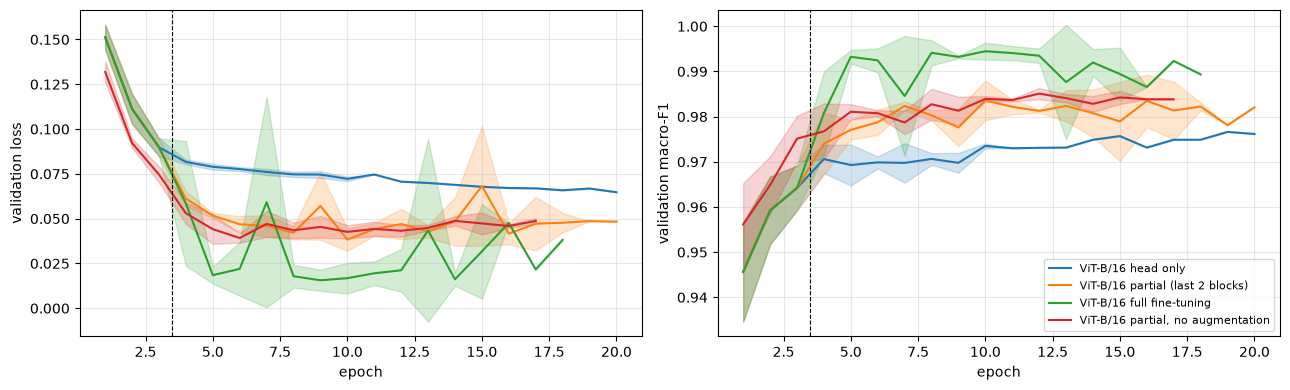

In [25]:
# Learning curves: mean over the seeds, shaded ± sd; dashed line: switch from head-only to fine-tuning
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k, (name, hs) in enumerate(vit_histories.items()):
    for ax, key in zip(axes, ("val_loss", "val_f1"), strict=True):
        epochs, mean, spread, _ = mean_curve(hs, key)
        ax.plot(epochs, mean, color=f"C{k}", label=name)
        ax.fill_between(epochs, mean - spread, mean + spread, color=f"C{k}", alpha=0.2)
for ax, label in zip(axes, ("validation loss", "validation macro-F1"), strict=True):
    ax.axvline(BASE_VIT.head_epochs + 0.5, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("epoch")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
finish("vit_learning_curves.png")

### 10.4 Test results of all strategies (after selection)

The selection above uses only the validation set. Afterwards, every strategy is evaluated once on the test set, as in Zhouyang's comparison, to show what the strategies achieve and cost. Strategies trained with the same seed share the initialisation and the first three epochs, so they are also compared seed by seed. The table of errors counts the test photos that every seed misclassifies and those misclassified at least once.

In [26]:
y_test = data.y_test
# predicted classes on the test set: vit_preds[strategy] is an array (seeds, N)
vit_preds = predict_labels(VIT_EXPERIMENTS, {"test": data.images[data.test_idx]})[
    "test"
]
test_f1 = seed_scores(vit_preds, y_test)  # macro-F1 of every seed
rows = []
for name, preds in vit_preds.items():
    rows.append(
        {
            "run": name,
            "test accuracy": mean_sd((preds == y_test).mean(1)),
            "test macro-F1": mean_sd(test_f1[name]),
            **stable_errors(preds, y_test),
            "train time (s)": training_cost(name)["train time (s)"],
        }
    )
vit_test = pd.DataFrame(rows).set_index("run")
vit_test.to_csv(out_path("vit_strategies_test.csv"))
vit_test

,test accuracy,test macro-F1,errors per seed,wrong in every seed,wrong at least once,train time (s)
run,,,,,,
ViT-B/16 head only,0.9815 ± 0.0046,0.9772 ± 0.0056,"12, 18, 12",11,19,220.4 ± 87.2
ViT-B/16 partial (last 2 blocks),0.9872 ± 0.0020,0.9839 ± 0.0021,"8, 10, 11",7,14,373.1 ± 52.8
ViT-B/16 full fine-tuning,0.9934 ± 0.0013,0.9917 ± 0.0013,"5, 4, 6",3,8,595.3 ± 116.4
"ViT-B/16 partial, no augmentation",0.9819 ± 0.0028,0.9764 ± 0.0033,"16, 13, 12",12,16,339.3 ± 34.9


In [27]:
# Same-seed comparisons on the test set (A - B in macro-F1)
names = list(VIT_EXPERIMENTS)
pairs = {
    "partial vs. head only": (names[1], names[0]),
    "full vs. partial": (names[2], names[1]),
    "augmentation vs. none (partial)": (names[1], names[3]),
}
vit_comparison = pd.DataFrame(
    {label: compare_seeds(test_f1[a], test_f1[b]) for label, (a, b) in pairs.items()}
).T
vit_comparison.to_csv(out_path("vit_strategy_comparison.csv"))
vit_comparison

,A - B (mean),A - B (sd),A higher in
partial vs. head only,0.006728,0.005872,3 of 3 seeds
full vs. partial,0.007747,0.00222,3 of 3 seeds
augmentation vs. none (partial),0.007468,0.005382,3 of 3 seeds


,healthy,Bacterial_spot,Early_blight,Late_blight
ViT-B/16 head only,1.0,0.9953,0.9525,0.9609
ViT-B/16 partial (last 2 blocks),1.0,0.9979,0.9675,0.9702
ViT-B/16 full fine-tuning,1.0,0.9990,0.9831,0.9846
"ViT-B/16 partial, no augmentation",1.0,0.9995,0.9535,0.9528


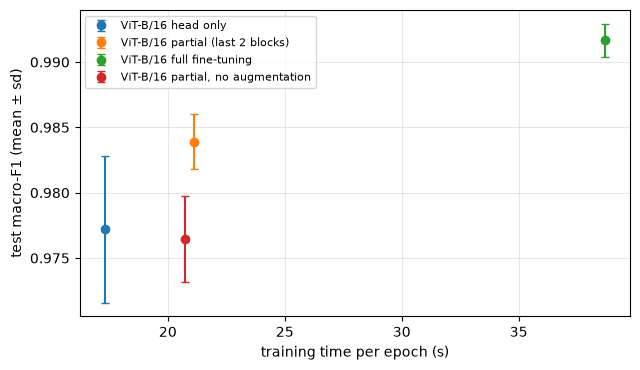

In [28]:
# Per-class test F1 (mean over seeds) and the accuracy-cost trade-off of the strategies
per_class = pd.DataFrame(
    {name: per_class_f1(preds, y_test) for name, preds in vit_preds.items()},
    index=SHORT_NAMES,
).T
display(per_class.round(4))

cost = pd.DataFrame(
    [training_cost(n) for n in VIT_EXPERIMENTS], index=list(VIT_EXPERIMENTS)
)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for k, name in enumerate(VIT_EXPERIMENTS):
    ax.errorbar(
        cost.at[name, "train s/epoch"],
        test_f1[name].mean(),
        yerr=sd(test_f1[name]),
        fmt="o",
        color=f"C{k}",
        label=name,
        capsize=3,
    )
ax.set_xlabel("training time per epoch (s)")
ax.set_ylabel("test macro-F1 (mean ± sd)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
finish("vit_strategy_cost.png")

# Part 4: Test Evaluation, Compute & Error Analysis

Sections 11–13: the final test evaluation of the three selected models over three seeds, their compute trade-offs and an error analysis with Grad-CAM and Score-CAM.

## 11. Final Test Evaluation (3 Seeds)

The three selected models (best custom CNN and ResNet18 from Section 9.3, best ViT strategy from Section 10.3) were trained with **3 training seeds** (62, 63, 64) on the same split. Each seed's best-validation checkpoint is evaluated **once** on the held-out test set. We report the **mean ± standard deviation over the seeds**, so a difference between models can be judged against the run-to-run variation. All seeds use the same test photos; the standard deviation does not cover a different choice of test leaves.

In [29]:
# the models selected on the validation set (Sections 9.3 and 10.3)
BEST_CNN, BEST_RESNET, BEST_VIT = load_final_models()
FINAL_MODELS = [BEST_CNN, BEST_RESNET, BEST_VIT]
y_test, seed0 = data.y_test, TRAIN_CONFIG["seeds"][0]

In [30]:
for name in FINAL_MODELS:
    run(name, data)  # loads the runs of Sections 9 and 10

# softmax probabilities on the test set: test_probs[model] is an array (seeds, N, K)
# (cached in OUT_DIR/runs/<run>/preds/)
test_probs = predict_probs(FINAL_MODELS, {"test": data.images[data.test_idx]})["test"]
# predicted classes: test_preds[model] is (seeds, N); [0] is the first seed
test_preds = {name: p.argmax(-1) for name, p in test_probs.items()}

rows = []
for name in FINAL_MODELS:
    for seed, y_pred in zip(TRAIN_CONFIG["seeds"], test_preds[name], strict=True):
        per_class = f1_score(y_test, y_pred, average=None)
        rows.append(
            {
                "model": name,
                "seed": seed,
                "accuracy": accuracy_score(y_test, y_pred),
                "macro_f1": f1_score(y_test, y_pred, average="macro"),
                **{f"F1 {s}": f for s, f in zip(SHORT_NAMES, per_class, strict=True)},
            }
        )
per_seed = pd.DataFrame(rows)
per_seed.to_csv(out_path("test_results_per_seed.csv"), index=False)

metrics = [c for c in per_seed.columns if c not in ("model", "seed")]
test_table = per_seed.groupby("model", sort=False)[metrics].agg(mean_sd)
test_table.to_csv(out_path("test_results.csv"))
print(f"Test set: {len(y_test)} images | mean ± sd over seeds {TRAIN_CONFIG['seeds']}")
test_table

Loaded finished run: SE-CNN lr=3e-3 (seed 62)
Loaded finished run: SE-CNN lr=3e-3 (seed 63)
Loaded finished run: SE-CNN lr=3e-3 (seed 64)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 (seed 62)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 (seed 63)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 (seed 64)
Loaded finished run: ViT-B/16 full fine-tuning (seed 62)
Loaded finished run: ViT-B/16 full fine-tuning (seed 63)
Loaded finished run: ViT-B/16 full fine-tuning (seed 64)


Test set: 756 images | mean ± sd over seeds [62, 63, 64]


,accuracy,macro_f1,F1 healthy,F1 Bacterial_spot,F1 Early_blight,F1 Late_blight
model,,,,,,
SE-CNN lr=3e-3,0.9841 ± 0.0040,0.9796 ± 0.0050,1.0000 ± 0.0000,0.9984 ± 0.0016,0.9596 ± 0.0105,0.9604 ± 0.0092
"ResNet18 two-stage + cosine, lr=1e-4",0.9885 ± 0.0008,0.9849 ± 0.0010,0.9989 ± 0.0019,1.0000 ± 0.0000,0.9722 ± 0.0018,0.9686 ± 0.0023
ViT-B/16 full fine-tuning,0.9934 ± 0.0013,0.9917 ± 0.0013,1.0000 ± 0.0000,0.9990 ± 0.0018,0.9831 ± 0.0033,0.9846 ± 0.0020


===== SE-CNN lr=3e-3 (seed 62) =====
                precision    recall  f1-score   support

       healthy     1.0000    1.0000    1.0000       148
Bacterial_spot     1.0000    1.0000    1.0000       320
  Early_blight     0.9542    0.9865    0.9701       148
   Late_blight     0.9852    0.9500    0.9673       140

      accuracy                         0.9881       756
     macro avg     0.9849    0.9841    0.9843       756
  weighted avg     0.9883    0.9881    0.9881       756

===== ResNet18 two-stage + cosine, lr=1e-4 (seed 62) =====
                precision    recall  f1-score   support

       healthy     1.0000    1.0000    1.0000       148
Bacterial_spot     1.0000    1.0000    1.0000       320
  Early_blight     0.9542    0.9865    0.9701       148
   Late_blight     0.9852    0.9500    0.9673       140

      accuracy                         0.9881       756
     macro avg     0.9849    0.9841    0.9843       756
  weighted avg     0.9883    0.9881    0.9881       756

==

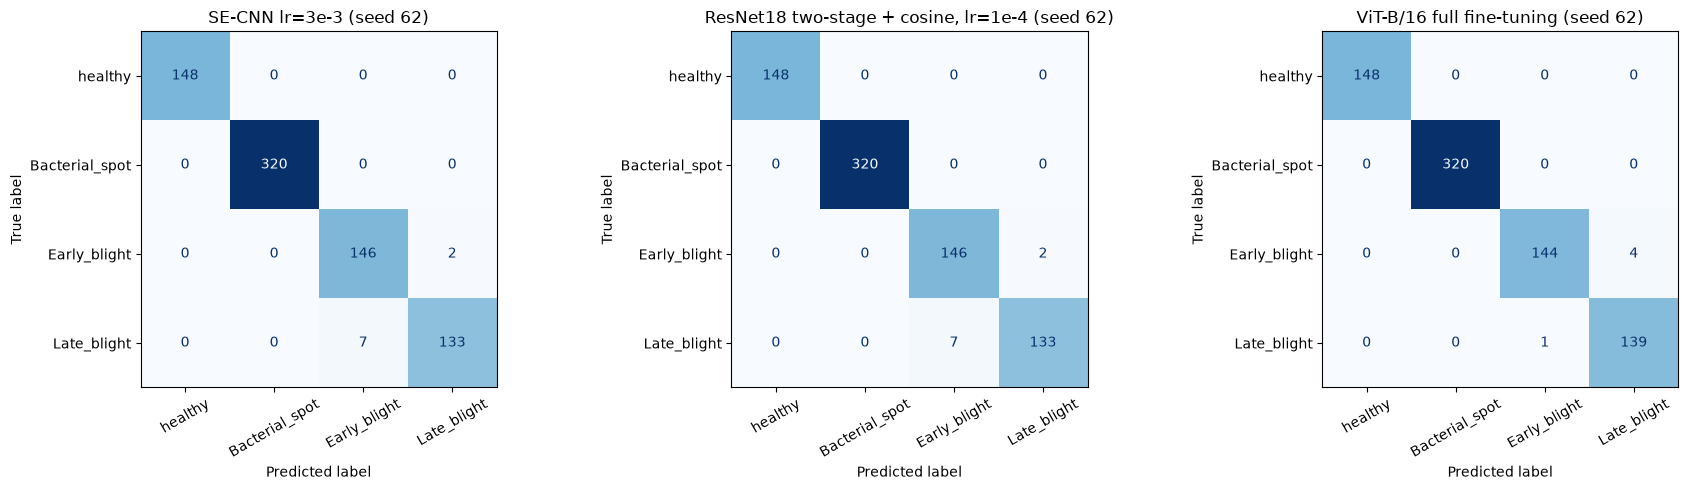

In [31]:
# Detailed report and confusion matrices (first seed)
for name in FINAL_MODELS:
    print(f"===== {name} (seed {seed0}) =====")
    print(
        classification_report(
            y_test,
            test_preds[name][0],
            target_names=SHORT_NAMES,
            digits=4,
        )
    )

fig, axes = plt.subplots(1, len(FINAL_MODELS), figsize=(6 * len(FINAL_MODELS), 5))
for ax, name in zip(axes, FINAL_MODELS, strict=True):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_preds[name][0],
        display_labels=SHORT_NAMES,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=30,
        ax=ax,
    )
    ax.set_title(f"{name} (seed {seed0})")
finish("confusion_matrices.png")

## 12. Compute Trade-offs

Accuracy is not the only criterion. A model for a farmer's phone must be small and fast, and a model that is expensive to train is harder to retrain on new data. For each final model:
- **inference** (checkpoint of the first seed): number of parameters, checkpoint size, latency for a single image and time per image in batches of 64, on the current device after a warm-up;
- **training** (mean over the seeds): trainable parameters in the fine-tuning stage, epochs trained, total training time without validation (device-synchronised) and seconds per epoch.

Training times depend on the number of epochs each model trained (at most CNN 50, ResNet18 16, ViT 15; early stopping can end a run sooner) and on the device.

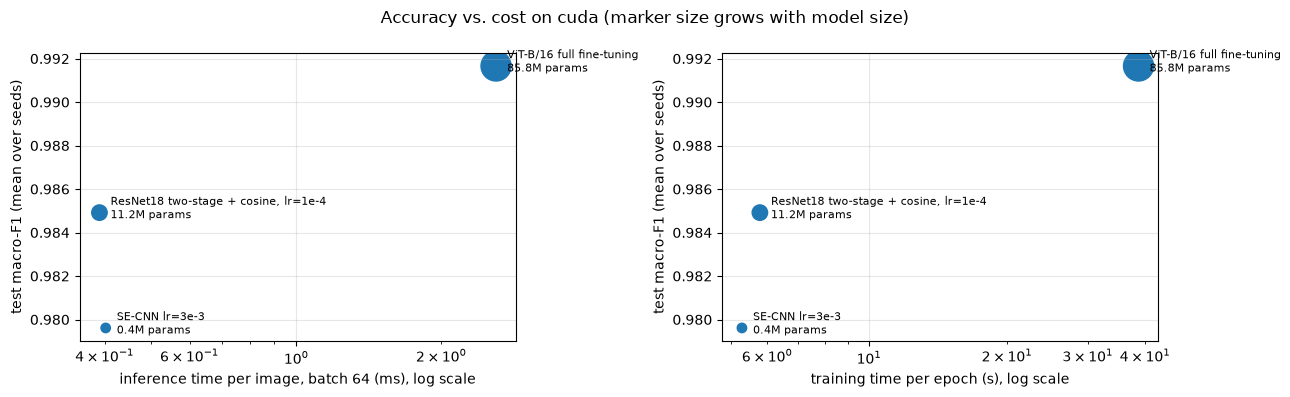

,params (M),size (MB),latency bs=1 (ms),ms/image bs=64,max epochs,trainable params,epochs trained,train time (s),train s/epoch,test macro-F1
model,,,,,,,,,,
SE-CNN lr=3e-3,0.4122,1.6654,1.7268,0.4020,50,412224,50.0 ± 0.0,264.1 ± 2.5,5.2816,0.9796
"ResNet18 two-stage + cosine, lr=1e-4",11.1786,44.7866,4.8412,0.3901,20,11178564,16.3 ± 1.5,94.2 ± 6.3,5.7795,0.9849
ViT-B/16 full fine-tuning,85.8017,343.2575,12.5041,2.5967,20,85801732,15.3 ± 2.5,595.3 ± 116.4,38.6919,0.9917


In [32]:
rows = []
for name in FINAL_MODELS:
    rows.append(
        {
            "model": name,
            **inference_cost(name),
            "max epochs": config_of(name).epochs,
            **training_cost(name),
            "test macro-F1": per_seed.loc[per_seed.model == name, "macro_f1"].mean(),
        }
    )
compute = pd.DataFrame(rows).set_index("model")
compute.to_csv(out_path("compute_tradeoffs.csv"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column, label in [
    (axes[0], "ms/image bs=64", "inference time per image, batch 64 (ms)"),
    (axes[1], "train s/epoch", "training time per epoch (s)"),
]:
    ax.scatter(
        compute[column],
        compute["test macro-F1"],
        s=40 + 4 * compute["size (MB)"] ** 0.8,
    )
    for name, r in compute.iterrows():
        ax.annotate(
            f"{name}\n{r['params (M)']:.1f}M params",
            (r[column], r["test macro-F1"]),
            textcoords="offset points",
            xytext=(8, -4),
            fontsize=8,
        )
    ax.set_xscale("log")
    ax.set_xlabel(f"{label}, log scale")
    ax.set_ylabel("test macro-F1 (mean over seeds)")
    ax.grid(alpha=0.3)
fig.suptitle(f"Accuracy vs. cost on {device.type} (marker size grows with model size)")
finish("compute_tradeoffs.png")
compute.round(4)

## 13. Error Analysis

### 13.1 Which classes are confused, how confident are the errors, and are they stable?
We pool the predictions of all seeds and list the most frequent (true → predicted) confusions, and the mean confidence of correct and wrong predictions. Confident errors are more dangerous than uncertain ones, because uncertain predictions could be flagged for a human expert. Following Zhouyang, we also count the test photos that **every seed** misclassifies: stable errors point to hard or mislabelled photos rather than to training randomness.

In [33]:
n_classes = len(DATA_CONFIG["classes"])
for name in FINAL_MODELS:
    preds = test_preds[name]  # (seeds, N)
    conf = test_probs[name].max(-1)  # confidence of every prediction, (seeds, N)
    wrong = preds != y_test
    # errors of all seeds together: confusion matrix without its diagonal
    cm = sum(confusion_matrix(y_test, p, labels=range(n_classes)) for p in preds)
    np.fill_diagonal(cm, 0)
    pairs = sorted(
        (
            (cm[i, j], SHORT_NAMES[i], SHORT_NAMES[j])
            for i in range(n_classes)
            for j in range(n_classes)
            if cm[i, j]
        ),
        reverse=True,
    )
    conf_wrong = conf[wrong].mean() if wrong.any() else float("nan")
    print(
        f"{name}: {cm.sum()} errors over {len(preds)} seeds"
        f" | mean confidence correct {conf[~wrong].mean():.3f}, wrong {conf_wrong:.3f}"
    )
    for count, t, p in pairs[:4]:
        print(f"    {t:15s} -> {p:15s} {count}")

stability = pd.DataFrame(
    {name: stable_errors(test_preds[name], y_test) for name in FINAL_MODELS}
).T
stability.to_csv(out_path("stable_errors.csv"))
display(stability)

SE-CNN lr=3e-3: 36 errors over 3 seeds | mean confidence correct 0.996, wrong 0.769
    Late_blight     -> Early_blight    20
    Early_blight    -> Late_blight     13
    Early_blight    -> Bacterial_spot  3
ResNet18 two-stage + cosine, lr=1e-4: 26 errors over 3 seeds | mean confidence correct 0.999, wrong 0.873
    Late_blight     -> Early_blight    18
    Early_blight    -> Late_blight     7
    Late_blight     -> healthy         1
ViT-B/16 full fine-tuning: 15 errors over 3 seeds | mean confidence correct 0.999, wrong 0.884
    Early_blight    -> Late_blight     9
    Late_blight     -> Early_blight    4
    Bacterial_spot  -> Early_blight    2


,errors per seed,wrong in every seed,wrong at least once
SE-CNN lr=3e-3,"9, 12, 15",6,19
"ResNet18 two-stage + cosine, lr=1e-4","9, 9, 8",4,13
ViT-B/16 full fine-tuning,"5, 4, 6",3,8


### 13.2 The most confident errors

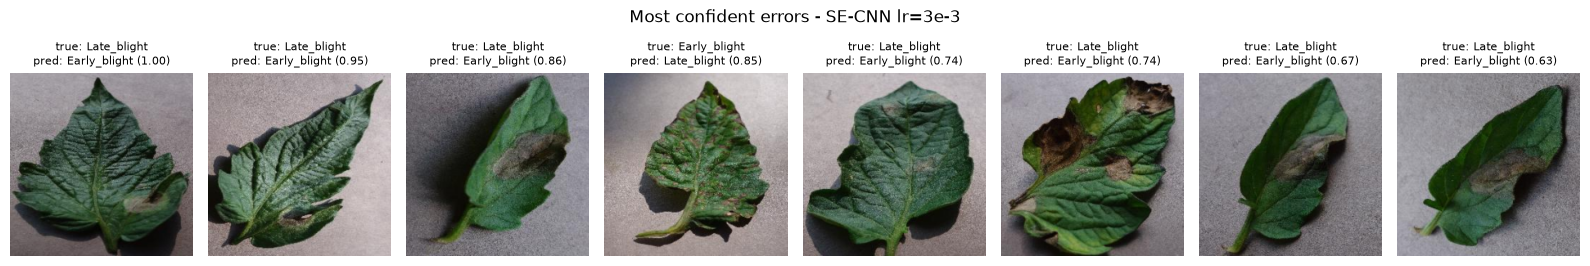

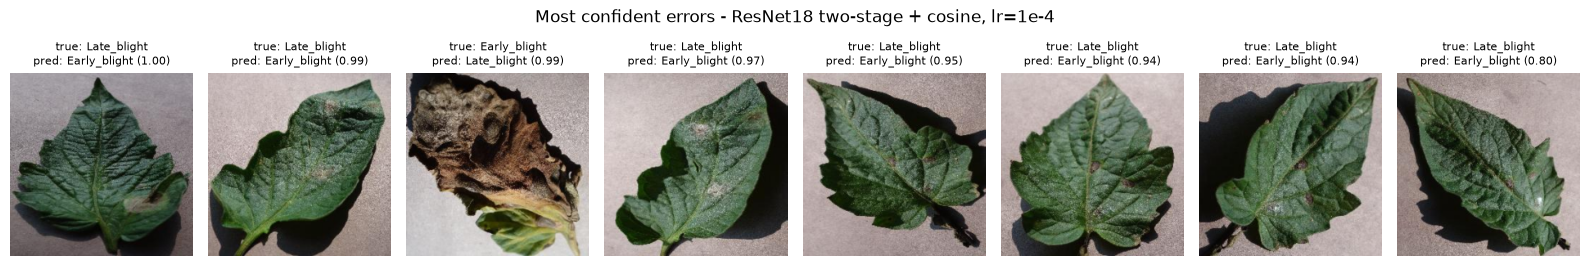

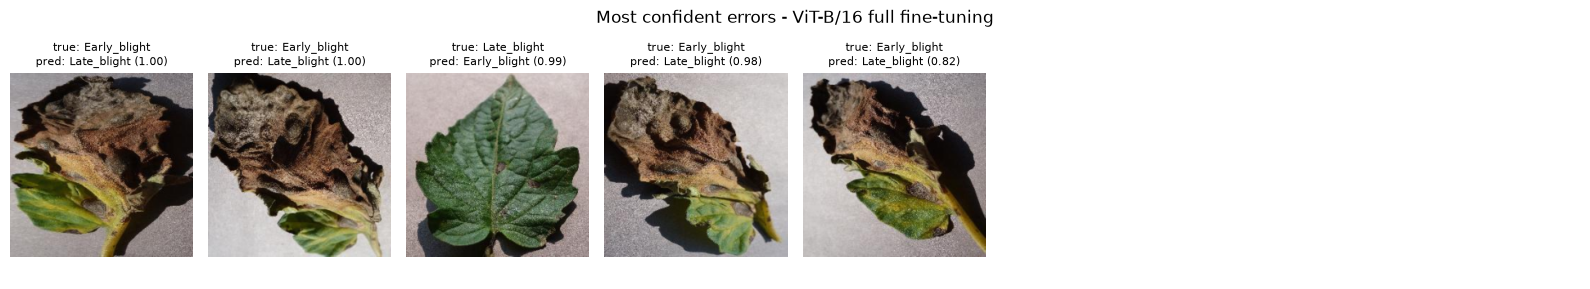

In [34]:
# Misclassified test images (first seed), sorted by confidence (most confident errors first)
for name in FINAL_MODELS:
    probs = test_probs[name][0]
    wrong = np.where(probs.argmax(1) != y_test)[0]
    wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]
    if len(wrong) == 0:
        print(f"{name}: no misclassified test images")
        continue
    fig, axes = plt.subplots(1, 8, figsize=(16, 2.9))
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, wrong, strict=False):
        ax.imshow(data.images[data.test_idx[i]].permute(1, 2, 0))
        ax.set_title(
            f"true: {SHORT_NAMES[y_test[i]]}\npred: {SHORT_NAMES[probs[i].argmax()]} ({probs[i].max():.2f})",
            fontsize=8,
        )
    fig.suptitle(f"Most confident errors - {name}")
    finish()

### 13.3 Grad-CAM: where do the models look?
Grad-CAM (Selvaraju et al., 2017) weights the feature maps of a late layer by the average gradient of the predicted class score. The result is a heat map of the image regions that drove the decision. If a model is right for the right reasons, the heat map lies on the **lesions or mite damage**. If it lies on the **background**, the model may be using a shortcut. We show the same test images (3 correct, up to 3 misclassified by the CNN) for all three final models.

The maps are computed with the [pytorch-grad-cam](https://github.com/jacobgil/pytorch-grad-cam) library (`cam_images` in `plantdisease/gradcam.py`). The target layers are:
- the last conv block for the custom CNN (14 × 14);
- `layer4` for ResNet18 (7 × 7);
- the LayerNorm before the attention of the last encoder block for the ViT. Its 196 patch tokens (the class token is dropped) are put back on their 14 × 14 grid, so the ViT gets a map just like the CNNs.

Every map is upsampled to 224 × 224 and scaled to [0, 1].

E:\Projects_2026\COMP7015_AI_Group_Project5-main\.venv\Lib\site-packages\torch\autograd\graph.py:1113: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\transformers\cuda\attention_backward.cu:951.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


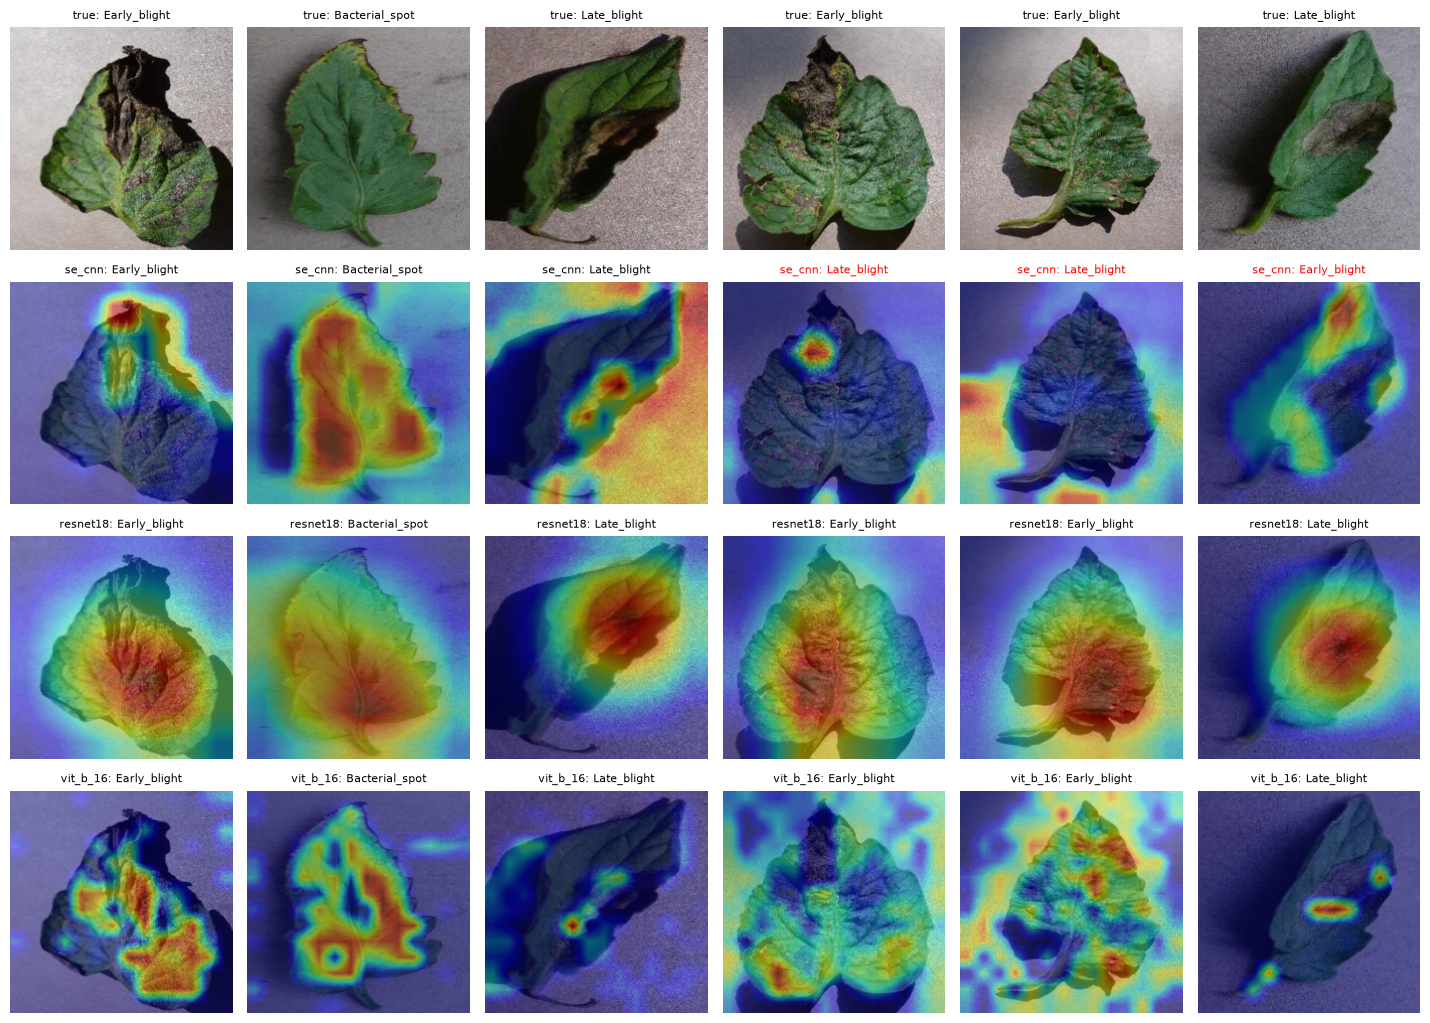

In [35]:
cnn_pred = test_preds[BEST_CNN][0]
rng_cam = np.random.default_rng(0)
examples = np.concatenate(
    [
        rng_cam.choice(np.where(cnn_pred == y_test)[0], 3, replace=False),
        np.where(cnn_pred != y_test)[0][:3],
    ]
)
example_images = data.images[data.test_idx[examples]]


def show_cams(method, file_name, models=FINAL_MODELS):
    # The example images (top row) and the heat map of every model (one row each, first seed);
    # the title is red where the model's prediction is wrong.
    fig, axes = plt.subplots(
        len(models) + 1,
        len(examples),
        figsize=(2.4 * len(examples), 2.6 * (len(models) + 1)),
        squeeze=False,
    )
    for col, i in enumerate(examples):
        axes[0, col].imshow(example_images[col].permute(1, 2, 0))
        axes[0, col].set_title(f"true: {SHORT_NAMES[y_test[i]]}", fontsize=8)
    for row, name in enumerate(models, start=1):
        cams = cam_images(name, seed0, example_images, method)
        preds = test_preds[name][0]
        for col, i in enumerate(examples):
            axes[row, col].imshow(example_images[col].permute(1, 2, 0))
            axes[row, col].imshow(cams[col], cmap="jet", alpha=0.45)
            axes[row, col].set_title(
                f"{config_of(name).arch}: {SHORT_NAMES[preds[i]]}",
                fontsize=8,
                color="black" if preds[i] == y_test[i] else "red",
            )
    for ax in axes.flat:
        ax.axis("off")
    finish(file_name)


show_cams("gradcam", "grad_cam.png")

### 13.4 Score-CAM: a gradient-free check
Gradients can be noisy or saturated, so Grad-CAM can point to the wrong place even when the model does not. Score-CAM (Wang et al., 2020) uses no gradients:
1. Each feature map of the same target layer is upsampled to the image size and scaled to [0, 1].
2. The image is masked with it, and the model's score for the predicted class on the masked image becomes that map's weight (softmax over the maps).
3. The heat map is the weighted sum of the feature maps.

Score-CAM needs one forward pass per feature map (256 for the CNN, 512 for ResNet18, 768 for the ViT), so it is much slower than Grad-CAM. We therefore use it only on the same six example images. Where the two methods agree, the heat map is a more reliable picture of what the model uses.

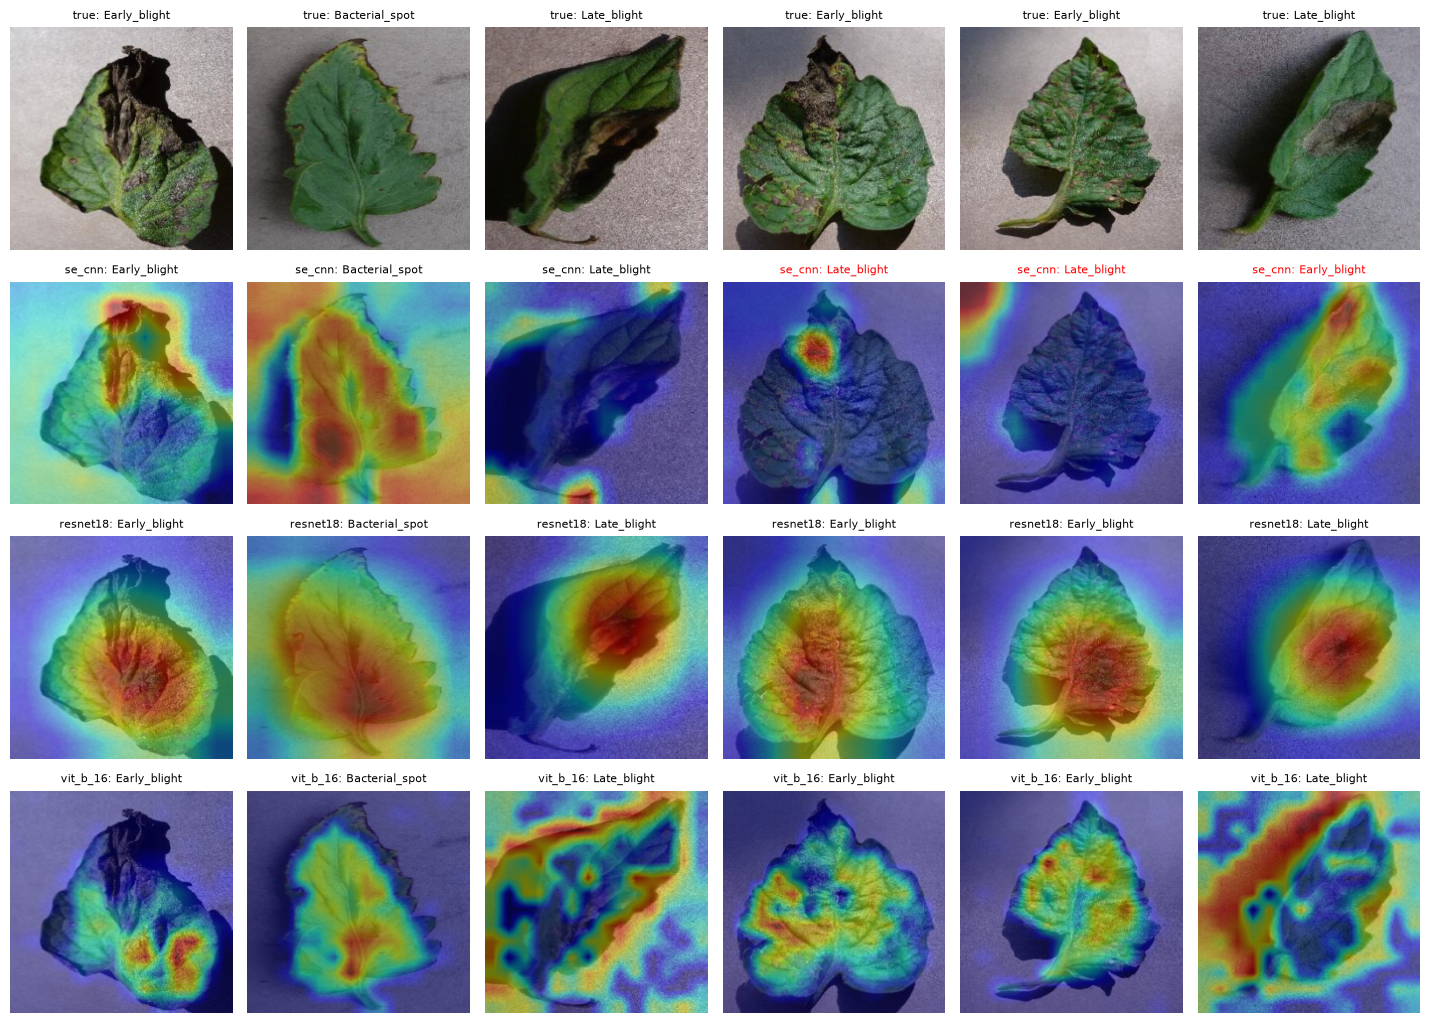

In [36]:
# Score-CAM maps of the same example images (first seed)
show_cams("scorecam", "score_cam.png")

# Part 5: Results Summary & Discussion

The key tables of Parts 1–4 in one place (Section 21) and their discussion (Sections 22.1–22.3). The robustness results are summarised and discussed at the end of `02_robustness.ipynb` (Sections 21 and 22.4–22.6).

## 21. Results Summary

Every table below is read from `OUT_DIR`, where the sections above save them. A missing table means that its section has not run yet. The robustness tables are collected at the end of `02_robustness.ipynb`.

In [37]:
TABLES = [
    ("Data: class counts per split", "class_counts.csv"),
    ("CNN / ResNet18 tuning and ablations, seed 62 (Section 9)", "tuning_results.csv"),
    ("CNN / ResNet18 selection with all seeds (Section 9.3)", "tuning_multi_seed.csv"),
    ("ViT strategies: validation and cost (Section 10.3)", "vit_validation.csv"),
    ("ViT strategies: test (Section 10.4)", "vit_strategies_test.csv"),
    (
        "ViT strategies: same-seed comparisons (Section 10.4)",
        "vit_strategy_comparison.csv",
    ),
    ("Final models on the test set (Section 11)", "test_results.csv"),
    (
        "Final models on the test set, seed by seed (Section 11)",
        "test_results_per_seed.csv",
    ),
    ("Compute trade-offs (Section 12)", "compute_tradeoffs.csv"),
    ("Errors that every seed makes (Section 13.1)", "stable_errors.csv"),
]

for title, file_name in TABLES:
    display(Markdown(f"**{title}** (`{file_name}`)"))
    path = out_path(file_name)
    if os.path.exists(path):
        display(pd.read_csv(path))
    else:
        display(Markdown("*not available yet*"))

**Data: class counts per split** (`class_counts.csv`)

,class_name,train,val,test,All,leaf ids
0,Tomato___healthy,699,152,148,999,250
1,Tomato___Bacterial_spot,1487,320,320,2127,532
2,Tomato___Early_blight,699,152,148,999,250
3,Tomato___Late_blight,644,136,140,920,230
4,All,3529,760,756,5045,1262


**CNN / ResNet18 tuning and ablations, seed 62 (Section 9)** (`tuning_results.csv`)

,run,arch,lr,batch,dropout,augment,class_w,schedule,best_epoch,val_acc,val_macro_f1,train_s_per_epoch
0,SE-CNN (full recipe),se_cnn,0.0010,32,0.3,True,True,cosine,43,0.993421,0.992313,5.556422
1,SE-CNN lr=3e-4,se_cnn,0.0003,32,0.3,True,True,cosine,39,0.992105,0.990063,5.557664
2,SE-CNN lr=3e-3,se_cnn,0.0030,32,0.3,True,True,cosine,43,0.993421,0.991808,5.338644
3,CNN (no attention),cnn,0.0010,32,0.3,True,True,cosine,27,0.992105,0.990141,4.257859
4,SE-CNN no augmentation,se_cnn,0.0010,32,0.3,False,True,cosine,30,0.992105,0.990064,5.343899
5,SE-CNN no dropout,se_cnn,0.0010,32,0.0,True,True,cosine,41,0.993421,0.991808,5.517426
6,SE-CNN no class weights,se_cnn,0.0010,32,0.3,True,False,cosine,45,0.993421,0.992313,5.606661
7,SE-CNN constant lr,se_cnn,0.0010,32,0.3,True,True,constant,17,0.989474,0.987087,5.581528
8,SE-CNN batch size 64,se_cnn,0.0010,64,0.3,True,True,cosine,50,0.990789,0.988823,5.317911
9,ResNet18 frozen backbone,resnet18,0.0001,32,0.0,True,True,constant,12,0.963158,0.956027,3.293133


**CNN / ResNet18 selection with all seeds (Section 9.3)** (`tuning_multi_seed.csv`)

,run,family,val macro-F1 (seed 62),mean over seeds,mean ± sd
0,SE-CNN (full recipe),cnn,0.992313,0.990642,0.9906 ± 0.0030
1,SE-CNN no class weights,cnn,0.992313,0.988409,0.9884 ± 0.0053
2,SE-CNN lr=3e-3,cnn,0.991808,0.990979,0.9910 ± 0.0007
3,"ResNet18 two-stage + cosine, lr=1e-4",resnet18,1.000000,1.000000,1.0000 ± 0.0000
4,ResNet18 weight decay 1e-2,resnet18,1.000000,1.000000,1.0000 ± 0.0000


... (10 outputs left out)

**Compute trade-offs (Section 12)** (`compute_tradeoffs.csv`)

,model,params (M),size (MB),latency bs=1 (ms),ms/image bs=64,max epochs,trainable params,epochs trained,train time (s),train s/epoch,test macro-F1
0,SE-CNN lr=3e-3,0.412224,1.665365,1.726805,0.401958,50,412224,50.0 ± 0.0,264.1 ± 2.5,5.281564,0.979611
1,"ResNet18 two-stage + cosine, lr=1e-4",11.178564,44.786635,4.841190,0.390130,20,11178564,16.3 ± 1.5,94.2 ± 6.3,5.779512,0.984916
2,ViT-B/16 full fine-tuning,85.801732,343.257525,12.504075,2.596692,20,85801732,15.3 ± 2.5,595.3 ± 116.4,38.691950,0.991660


**Errors that every seed makes (Section 13.1)** (`stable_errors.csv`)

,Unnamed: 0,errors per seed,wrong in every seed,wrong at least once
0,SE-CNN lr=3e-3,"9, 12, 15",6,19
1,"ResNet18 two-stage + cosine, lr=1e-4","9, 9, 8",4,13
2,ViT-B/16 full fine-tuning,"5, 4, 6",3,8


## 22. Discussion

Unless stated otherwise, scores are the macro-F1 on the 756 test photos, given as mean ± sd over the three training seeds. "Higher in k of 3 seeds" compares two models trained with the same seeds. All numbers come from the tables in Section 21.

**In short.** On clean PlantVillage photos all three models are almost perfect (macro-F1 0.980–0.992). The ViT is ahead in every seed, but the gap is a few photos. The clean score says little about the models outside the training conditions: `02_robustness.ipynb` tests them there (Sections 14–20) and continues this discussion in Sections 22.4–22.6.

### 22.1 Data protocol (Sections 1–6)

- Grouping by leaf leaves 5,045 of the 6,627 photos, from 1,262 physical leaves: 3,529 / 760 / 756 photos for train / validation / test. No leaf id crosses two splits. The 1,582 excluded photos are 1,038 greenhouse photos whose leaf number can only be read from the file name (590 healthy, 448 late blight) and 544 photos without any leaf information (541 of them late blight). Bacterial spot has about 2.1× more photos than each other class, which the CNNs balance with class weights (0.59 against 1.26–1.37).
- **The background alone predicts the class.** A random forest that sees only the mean colour of the four image corners reaches 82.1% accuracy (macro-F1 0.791) on the validation photos. Uniform guessing gives 25%, and always answering bacterial spot gives 42% (macro-F1 0.148). Because the backgrounds differ between the classes, a model can reach a high clean score without looking at the disease. `02_robustness.ipynb` therefore tests the background in several ways.

### 22.2 Models and tuning (Sections 7–10)

- **The validation set is saturated.** Every SE-CNN recipe reaches a validation macro-F1 of 0.987–0.992 on seed 62, and one validation error moves the accuracy by 0.0013. The ablations differ from the full recipe (0.992) by at most 0.005: constant learning rate 0.987, batch size 64 0.989, without SE attention 0.990, without augmentation 0.990, without dropout or class weights 0.992. The full recipe itself varies by ±0.003 over the three seeds (0.991 ± 0.003). **None of these single-seed ablations can therefore be separated from the seed-to-seed variation.** Re-running the finalists with all seeds selected the SE-CNN with lr = 3e-3, with the highest mean and the smallest spread (0.991 ± 0.001). Without class weights the mean is lowest and the spread largest (0.988 ± 0.005).
- **ResNet18.** Every recipe that fine-tunes the backbone reaches 0.997–1.000 on seed 62. Only freezing the backbone costs clearly (0.956), the one ablation effect well above the seed noise. Two-stage fine-tuning with a cosine schedule and lr = 1e-4 was selected (1.000 ± 0.000 over the seeds). The same recipe with weight decay 1e-2 is exactly tied.
- **ViT strategies.** Unfreezing more of the ViT improves the test score in every seed. Head only reaches 0.977 ± 0.006, the last two blocks 0.984 ± 0.002 and full fine-tuning 0.992 ± 0.001. Partial minus head only is +0.007 ± 0.006 and full minus partial is +0.008 ± 0.002, both higher in 3 of 3 seeds. The number of test photos that every seed misclassifies falls from 11 to 7 to 3. The price is compute. Trainable parameters grow from 3 k to 14.2 M to 85.8 M, the time per epoch from 17.3 to 21.1 to 38.7 s (2.2×), and the total training time from 220 to 373 to 595 s (2.7×). Full fine-tuning stops early after 15.3 ± 2.5 of 20 epochs.
- **Augmentation** helps the partial ViT on the clean test: 0.984 against 0.976 without it (+0.007 ± 0.005, higher in 3 of 3 seeds), and 7 instead of 12 photos wrong in every seed. Flips, 90° rotations and a mild brightness jitter thus add useful variation even though the test leaves look like the training leaves. Whether augmentation helps under the changes of Sections 14–20 was not tested separately.

### 22.3 Clean test, compute and errors (Sections 11–13)

| | SE-CNN (lr 3e-3) | ResNet18 (two-stage + cosine) | ViT-B/16 (full FT) |
|---|---|---|---|
| test macro-F1 | 0.980 ± 0.005 | 0.985 ± 0.001 | 0.992 ± 0.001 |
| errors per seed (of 756) | 9, 12, 15 | 9, 9, 8 | 5, 4, 6 |
| parameters / checkpoint size | 0.41 M / 1.7 MB | 11.2 M / 44.8 MB | 85.8 M / 343 MB |
| latency batch 1 / per image in batches of 64 | 2.0 / 0.35 ms | 2.6 / 0.37 ms | 6.3 / 2.49 ms |
| epochs trained (max) / training time | 50 (50) / 264 s | 16.3 (20) / 94 s | 15.3 (20) / 595 s |

- **Ranking.** The order is ViT > ResNet18 > SE-CNN: on average 5.0, 8.7 and 12.0 wrong photos per seed. Seed by seed, the ViT beats ResNet18 in 3 of 3 seeds. ResNet18 beats the SE-CNN in 2 of 3 seeds, and on seed 62 both score exactly the same. The ViT's lead is consistent and agrees with the gains of Section 10, but it amounts to only 3–4 photos. ResNet18 is the most stable over the seeds (±0.001), the SE-CNN the least (±0.005).
- **Confusions.** Healthy and bacterial spot are recognised almost perfectly (F1 ≥ 0.998 for every model). Almost all errors lie between **early blight and late blight**: 33 of 36 pooled errors of the SE-CNN, 25 of 26 of ResNet18 and 13 of 15 of the ViT. The two CNNs mostly call late blight early blight (20 and 18), while the ViT more often makes the opposite mistake (9 of 15). Wrong predictions are less confident than correct ones: mean confidence 0.77, 0.87 and 0.88, against at least 0.996 for correct predictions. Section 20 builds on this.
- **Stable errors.** Only 6 (SE-CNN), 4 (ResNet18) and 3 (ViT) test photos are misclassified by every seed, while 19, 13 and 8 photos are wrong in at least one seed. Most errors therefore depend on the seed. There is little sign of mislabelled test photos; the errors are borderline blight photos that tip one way or the other with the training randomness.
- **Compute.** The SE-CNN is 27× smaller than ResNet18 and the fastest on single images (2.0 ms). It still trains the longest of the two CNNs (264 s against 94 s), because it uses all 50 epochs and never stops early. ResNet18 is the cheapest to train and in batches as fast as the SE-CNN. Compared with ResNet18, the ViT gains 0.007 macro-F1 for 7.7× the parameters, 6.3× the training time and 2.4× the single-image latency (6.8× in batches). At 343 MB and 6.3 ms per photo it suits a server better than a phone. All times come from one CUDA GPU with mixed precision and are comparable only within this table.